# **M4 Grood DINO Implementation**

## **0. Importing and Model fetching**
Model page: https://huggingface.co/facebook/dinov3-vits16-pretrain-lvd1689m

⚠️ If the generated code snippets do not work, please open an issue on either the [model repo](https://huggingface.co/facebook/dinov3-vits16-pretrain-lvd1689m)
			and/or on [huggingface.js](https://github.com/huggingface/huggingface.js/blob/main/packages/tasks/src/model-libraries-snippets.ts) 🙏

The model you are trying to use is gated. Please make sure you have access to it by visiting the model page.To run inference, either set HF_TOKEN in your environment variables/ Secrets or run the following cell to login. 🤗

In [76]:
import torchvision.datasets as datasets
import torch.optim as optim
import torch
import torch.nn as nn
import numpy as np
import torchvision
from transformers import pipeline
from torch.utils.data import DataLoader, TensorDataset
import torchvision.transforms as transforms
from transformers import AutoImageProcessor, AutoModel
from tqdm.auto import tqdm
import h5py
import os
import kagglehub
from torchvision.datasets import ImageFolder
import matplotlib.pyplot as plt
from torch.distributions import MultivariateNormal

In [ ]:
!pip install -U transformers

In [ ]:
from huggingface_hub import login
login(new_session=False)

In [3]:
# Load model directly
from transformers import AutoImageProcessor, AutoModel

processor = AutoImageProcessor.from_pretrained("facebook/dinov3-vits16-pretrain-lvd1689m")
model = AutoModel.from_pretrained("facebook/dinov3-vits16-pretrain-lvd1689m")

preprocessor_config.json:   0%|          | 0.00/585 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/743 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/86.4M [00:00<?, ?B/s]

In [19]:
device = "cuda" if torch.cuda.is_available() else "cpu"

## **1. GROOD**
In this part we are going to implement the **Calibrated Out-of-Distribution Detection with a Generic Representation** method by Tomáš Vojíř, Jan Šochman, Rahaf Aljundi, and Jiří Matas. The paper can be found [here](https://ieeexplore.ieee.org/document/10350539?denied=).

<img src="https://mrs.fel.cvut.cz/images/images/logo_FEE_CTU.png" alt="FEE CTU logo" width="60%">

### **1.1 Core Idea**
The core idea is to use a generic, pre-trained feature extractor and combine the scores of two simple classifiers: Linear Probe (LP) and Nearest Mean (NM)—which are trained only on in-distribution (ID) data.

### **1.2 Linear Probe**

*Definition*

The LP classifier is a single linear projection layer (e.g., torch.nn.Linear) followed by a softmax. This is a standard multi-class logistic regression model.

*LP Scores*

For OOD detection, the paper uses the Maximum Logit score (i.e., the highest logit value before the softmax).

### **1.3 Nearest Mean**

*Definition*

The Nearest Mean (NM) classifier is a simple classifier that assigns a sample to the class whose mean feature vector is closest to the sample's feature vector.

*NM Scores*

The paper uses an L2​ distance-based similarity score.



### **1.4 Model the ID Distribution in 2D Score Space**
For every ID training sample: its `LP_score` and its `NM_score`. The next step is to model the distribution of these scores.
1.   Create 2D Score Vectors `(LP_score, NM_score)`
2.   Model Per-Class
3.   Fit 2D Gaussians


### **1.5 Model a "General" OOD Distribution**
To create a calibrated decision boundary, we need a model for the OOD data, `p(x∣O)`. The paper constructs a single 2D Normal distribution to represent a "general" OOD sample.

OOD Model Parameters:
*   Mean
*   Covariance



### **1.6 Neyman-Pearson Task**
In the GROOD implementation, the Neyman-Pearson task is used to create an optimal, calibrated decision boundary between in-distribution (ID) and out-of-distribution (OOD) data.

## **2. Datasets**
For our experiment we will use the most basic datasets to showcase the different characteristics of feature vectors.

We will need to define a transform to preprocess the images before feeding them into the model. Vision Transformers (like DINOv3) have strict requirements for their input data, as they were pre-trained on a specific data distribution, resolution, and format.

Our transform pipeline must accomplish two critical tasks:

* **1. Resolution Matching:** Our datasets (CIFAR, SVHN) are composed of small 32x32 pixel images. The DINOv3 model was trained on much higher-resolution images (e.g., 224x224). Our transform must resize these small images to match the model's expected input dimensions.
* **2. Data Normalization:** This is the most critical step. The model expects pixel values to be normalized using the *exact* **`mean`** and **`standard deviation`** of the massive dataset it was trained on. If we feed it images with pixel values from 0-255 or 0-1, the resulting feature vectors will be meaningless.

To ensure this is done correctly, we will use the `AutoImageProcessor` associated with the DINOv3 model from Hugging Face. This processor automatically handles the correct resizing, cropping, and normalization, guaranteeing our data is in the perfect format for feature extraction.

In [5]:
transform = transforms.ToTensor()

### 2.1 CIFAR-10 and CIFAR-100
The CIFAR-10 and CIFAR-100 datasets are widely used benchmark datasets for image classification tasks in machine learning and computer vision.
- **CIFAR-10**: This dataset consists of 60,000 32x32 color images in 10 different classes, with 6,000 images per class. The classes include airplanes, cars, birds, cats, deer, dogs, frogs, horses, ships, and trucks. The dataset is divided into 50,000 training images and 10,000 test images.
- **CIFAR-100**: Similar to CIFAR-10, this dataset also contains 60,000 32x32 color images, but it is divided into 100 classes with 600 images per class. The 100 classes are grouped into 20 superclasses, providing a more fine-grained classification challenge. Like CIFAR-10, CIFAR-100 is also split into 50,000 training images and 10,000 test images.

In [6]:
cifar10_train = datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
cifar10_test = datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)

print(f"Loaded CIFAR-10: {len(cifar10_train)} train images, {len(cifar10_test)} test images.")

100%|██████████| 170M/170M [00:04<00:00, 35.2MB/s]


Loaded CIFAR-10: 50000 train images, 10000 test images.


In [ ]:
dataset_cifar100 = torchvision.datasets.CIFAR100(root='./data', train=False, download=True, transform=transform)
loader_cifar100 = DataLoader(dataset_cifar100, batch_size=64, shuffle=False, num_workers=2)
print(f"Amount of CIFAR100 samples (OOD - CIFAR-100): {len(dataset_cifar100)}")

### 2.2 SVHN
The Street View House Numbers (SVHN) dataset is a real-world image dataset for developing machine learning and object recognition algorithms with a focus on digit recognition in natural images. It is derived from Google Street View images and contains over 600,000 labeled digits (0-9) cropped from house numbers in street-level photographs.

In [7]:
svhn_train = datasets.SVHN(root='./data', split='train', download=True, transform=transform)
svhn_test = datasets.SVHN(root='./data', split='test', download=True, transform=transform)

print(f"Loaded SVHN: {len(svhn_train)} train images, {len(svhn_test)} test images.")

100%|██████████| 182M/182M [00:10<00:00, 18.1MB/s]
100%|██████████| 64.3M/64.3M [00:07<00:00, 8.53MB/s]


Loaded SVHN: 73257 train images, 26032 test images.


### 2.3 FOOD101


In [8]:
food101_train = datasets.Food101(root='./data', split='train', download=True, transform=transform)
food101_test = datasets.Food101(root='./data', split='test', download=True, transform=transform)

print(f"Loaded Food-101: {len(food101_train)} train images, {len(food101_test)} test images.")

100%|██████████| 5.00G/5.00G [02:49<00:00, 29.5MB/s]


Loaded Food-101: 75750 train images, 25250 test images.


In [10]:
flowers_train = datasets.Flowers102(root='./data', split='train', download=True, transform=transform)
flowers_val = datasets.Flowers102(root='./data', split='val', download=True, transform=transform)
flowers_test = datasets.Flowers102(root='./data', split='test', download=True, transform=transform)

print(f"Loaded Flowers 102: {len(flowers_train)} train, {len(flowers_val)} val, {len(flowers_test)} test images.")

100%|██████████| 345M/345M [00:11<00:00, 30.9MB/s]
100%|██████████| 502/502 [00:00<00:00, 1.45MB/s]
100%|██████████| 15.0k/15.0k [00:00<00:00, 5.63MB/s]

Loaded Flowers 102: 1020 train, 1020 val, 6149 test images.


### 2.4 Pokémon Dataset (Bonus)
The Pokémon dataset is a collection of images featuring various Pokémon characters from the popular franchise. It is often used for image classification tasks in machine learning and computer vision.
It uses the original Gen 1 Pokémon (151 characters) as classes.

<img src="https://static0.gamerantimages.com/wordpress/wp-content/uploads/2023/06/pokemon-fusion-art-kanto-gen-1.jpg" width="60%">

In [ ]:
path = kagglehub.dataset_download("thedagger/pokemon-generation-one")

In [ ]:
transform_kaggle = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5],
                         std=[0.5, 0.5, 0.5])
])

image_root_path = os.path.join(path, 'dataset')

dataset_pokemon_gen1 = ImageFolder(
    root=image_root_path,
    transform=transform_kaggle
)

loader_pokemon_gen1 = DataLoader(
    dataset_pokemon_gen1,
    batch_size=64,
    shuffle=False,
    num_workers=2
)

print(f"\n✅ Success! Loaded {len(dataset_pokemon_gen1)} images.")
print(f"Found classes: {dataset_pokemon_gen1.classes[:5]}...")

## **3. Feature Extraction**
Because we already extracted the features in the previous `m3` notebook we can just skip to step `3.3`

### **3.1 Utility**
Utility function to extract feature vectors and save it to a `h5_file`.
Later in the code also check that the file is only created

In [11]:
def extract_and_save_to_file(model, loader, filename, device):
    """
    Runs the model on all data from the loader and saves features and labels
    to a NEW, SEPARATE HDF5 file.
    """

    if os.path.exists(filename):
        print(f"File {filename} already exists. Skipping extraction.")
        return

    print(f"Processing data, saving to: {filename}...")
    all_features = []
    all_labels = []

    desc = os.path.basename(filename).replace('.h5', '')

    with torch.inference_mode():
        for images, labels in tqdm(loader, desc=f"Extraction {desc}"):
            images = images.to(device)
            outputs = model(pixel_values=images)
            features = outputs.pooler_output
            all_features.append(features.cpu().numpy())
            all_labels.append(labels.cpu().numpy())

    all_features = np.concatenate(all_features)
    all_labels = np.concatenate(all_labels)

    with h5py.File(filename, 'w') as f:
        f.create_dataset("features", data=all_features)
        f.create_dataset("labels", data=all_labels)

    print(f"Finished {desc}. Saved {all_features.shape[0]} samples to {filename}.")

### **3.2 Extracting and saving**

In [ ]:
output_dir = "features"
os.makedirs(output_dir, exist_ok=True)

extract_and_save_to_file(model, loader_cifar10, os.path.join(output_dir, "cifar10.h5"), device)
extract_and_save_to_file(model, loader_cifar100, os.path.join(output_dir, "cifar100.h5"), device)
extract_and_save_to_file(model, loader_svhn, os.path.join(output_dir, "svhn.h5"), device)
extract_and_save_to_file(model, loader_food101, os.path.join(output_dir, "food101.h5"), device)
extract_and_save_to_file(model, loader_pokemon_gen1, os.path.join(output_dir, "pokemon.h5"), device)

### **3.3 Reading the features into `np.arrays`**


In [14]:
with h5py.File('features/cifar10.h5', 'r') as f:
    cifar10_features = np.array(f['features'])
    cifar10_labels = np.array(f['labels'])

In [15]:
with h5py.File('features/cifar100.h5', 'r') as f:
    cifar100_features = np.array(f['features'])
    cifar100_labels = np.array(f['labels'])

In [16]:
with h5py.File('features/svhn.h5', 'r') as f:
    svhn_features = np.array(f['features'])
    svhn_labels = np.array(f['labels'])

In [17]:
with h5py.File('features/food101.h5', 'r') as f:
    food101_features = np.array(f['features'])
    food101_labels = np.array(f['labels'])

In [18]:
with h5py.File('features/pokemon.h5', 'r') as f:
    pokemon_features = np.array(f['features'])
    pokemon_labels = np.array(f['labels'])

## **4. LP and NM Classifier**

### **4.1 General Hyperparameters**

In [33]:
learning_rate = 0.001
batch_size = 256
num_epochs = 100

### **4.2 Classifiers for CIFAR-10**

In [22]:
feature_dim = cifar10_features.shape[1]
num_classes = 10

### **4.2.1  🚀 Linear Probe (LP)**

In [31]:
# --- 1. Define the LP Model ---
cifar10_lp_classifier = nn.Linear(feature_dim, num_classes)

# --- 2. Create DataLoader for training ---
cifar10_features_tensor = torch.from_numpy(cifar10_features)
cifar10_labels_tensor = torch.from_numpy(cifar10_labels).long()

cifar10_feature_dataset = TensorDataset(cifar10_features_tensor, cifar10_labels_tensor)
cifar10_feature_loader = DataLoader(cifar10_feature_dataset, batch_size=batch_size, shuffle=True)

# --- 3. Set up for Training ---
cifar10_lp_classifier.to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(cifar10_lp_classifier.parameters(), lr=learning_rate)

In [34]:
# --- 4. Training loop ---
cifar10_lp_classifier.train()
print(f"Starting LP classifier training...")

for epoch in range(num_epochs):
    total_loss = 0

    progress_bar = tqdm(cifar10_feature_loader, desc=f"Epoch {epoch+1}/{num_epochs}", leave=False)

    for features, labels in progress_bar:
        features = features.to(device)
        labels = labels.to(device)

        # Forward pass
        outputs = cifar10_lp_classifier(features)
        loss = criterion(outputs, labels)

        # Backward and optimize
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

        progress_bar.set_postfix(loss=f"{loss.item():.4f}")

    if (epoch + 1) % 10 == 0 or (epoch + 1) == num_epochs:
        print(f"Epoch [{epoch+1}/{num_epochs}], Avg. Loss: {total_loss / len(cifar10_feature_loader):.4f}")

cifar10_lp_classifier.eval()
print("LP classifier training complete!")

Starting LP classifier training...


Epoch 1/100:   0%|          | 0/40 [00:00<?, ?it/s]

Epoch 2/100:   0%|          | 0/40 [00:00<?, ?it/s]

Epoch 3/100:   0%|          | 0/40 [00:00<?, ?it/s]

Epoch 4/100:   0%|          | 0/40 [00:00<?, ?it/s]

...

Epoch 97/100:   0%|          | 0/40 [00:00<?, ?it/s]

Epoch 98/100:   0%|          | 0/40 [00:00<?, ?it/s]

Epoch 99/100:   0%|          | 0/40 [00:00<?, ?it/s]

Epoch 100/100:   0%|          | 0/40 [00:00<?, ?it/s]

Epoch [100/100], Avg. Loss: 0.0345
LP classifier training complete!


### 🧭 **4.2.2 Nearest Mean (NM)**

In [35]:
nm_class_means = torch.zeros(num_classes, feature_dim).to(device)

print("Calculating NM classifier means...")

# --- 2. Loop through each class and calculate its mean ---
for k in range(num_classes):
    class_k_features = cifar10_features_tensor[cifar10_labels_tensor == k]

    if len(class_k_features) > 0:
        nm_class_means[k] = class_k_features.mean(dim=0)
    else:
        print(f"Warning: No samples found for class {k}")

print("NM classifier calculation complete!")
print(f"Class means tensor shape: {nm_class_means.shape}")

Calculating NM classifier means...
NM classifier calculation complete!
Class means tensor shape: torch.Size([10, 384])


## **4.3 SVHN**

In [ ]:
svhn_feature_dim = svhn_features.shape[1]
svhn_num_classes = svhn_labels.shape[1]

## **5. Calculating the scores**
Calculate the two scores (LP score and NM score) for every single sample in our ID dataset

### **5.1 CIFAR-10 scores**

In [37]:
cifar10_lp_classifier.eval()

with torch.no_grad():
    all_logits = cifar10_lp_classifier(cifar10_features_tensor)
    cifar10_lp_scores, _ = torch.max(all_logits, dim=1)

print(f"LP scores calculated. Shape: {cifar10_lp_scores.shape}")

LP scores calculated. Shape: torch.Size([10000])


In [39]:
with torch.no_grad():
    correct_class_means = nm_class_means[cifar10_labels_tensor]

    # Calculate the L2 distance (squared)
    # This is (feature - mean)^2
    l2_distance_sq = torch.sum((cifar10_features_tensor - correct_class_means)**2, dim=1)

    l2_distance = torch.sqrt(l2_distance_sq)

    cifar10_nm_scores = 1.0 / (1.0 + l2_distance)

print(f"NM scores calculated. Shape: {cifar10_nm_scores.shape}")

NM scores calculated. Shape: torch.Size([10000])


In [40]:
cifar10_lp_scores_2d = cifar10_lp_scores.unsqueeze(1)
cifar10_nm_scores_2d = cifar10_nm_scores.unsqueeze(1)

cifar10_id_score_vectors = torch.cat((cifar10_lp_scores_2d, cifar10_nm_scores_2d), dim=1)

print(f"Shape: {cifar10_id_score_vectors.shape}")

Shape: torch.Size([10000, 2])


## **6. Fitting into the 2D Gaussian models**
The paper specifies that we should fit one 2D Gaussian for each ID class. ☹

### **6.1 CIFAR-10**

In [43]:
print("Fitting 2D Gaussian models for each ID class...")

cifar10_id_class_score_means = torch.zeros(num_classes, 2).to(device)
cifar10_id_class_covs = torch.zeros(num_classes, 2, 2).to(device)

cifar10_score_vectors = cifar10_id_score_vectors.to(device)

for k in range(num_classes):
    class_k_scores = cifar10_score_vectors[cifar10_labels_tensor == k]

    if len(class_k_scores) > 0:
        cifar10_id_class_score_means[k] = class_k_scores.mean(dim=0)

        # Calculate the 2x2 covariance matrix for this class
        # torch.cov() expects [features, observations], so we transpose (T)
        cifar10_id_class_covs[k] = torch.cov(class_k_scores.T)
    else:
        print(f"Warning: No samples found for class {k}!")

print("Successfully fitted all 10 ID class Gaussian models.")
print(f"Class means shape: {cifar10_id_class_score_means.shape}")
print(f"Class covariances shape: {cifar10_id_class_covs.shape}")

Fitting 2D Gaussian models for each ID class...
Successfully fitted all 10 ID class Gaussian models.
Class means shape: torch.Size([10, 2])
Class covariances shape: torch.Size([10, 2, 2])


## **7. Creating an OOD model**

### **7.1 General functions**

In [48]:
def create_ood_model(id_score_vectors, multiplier=10.0):
    """
    Creates the general OOD model (mean and covariance) based on
    the range of the provided ID score vectors.

    Args:
        id_score_vectors (torch.Tensor): The [N, 2] tensor of ID scores.
        multiplier (float, optional): Factor to broaden the OOD variance.

    Returns:
        tuple: (ood_model_mean, ood_model_cov)
               - ood_model_mean (torch.Tensor): [2] mean vector ([0, 0]).
               - ood_model_cov (torch.Tensor): [2, 2] diagonal covariance matrix.
    """

    print("Modeling the general OOD distribution...")

    device = id_score_vectors.device

    ood_model_mean = torch.tensor([0.0, 0.0], device=device)
    id_range_lp = torch.quantile(torch.abs(id_score_vectors[:, 0]), 0.9)
    id_range_nm = torch.quantile(id_score_vectors[:, 1], 0.9)

    ood_var_lp = (multiplier * id_range_lp)**2
    ood_var_nm = (multiplier * id_range_nm)**2

    ood_model_cov = torch.tensor([
        [ood_var_lp, 0.0],
        [0.0, ood_var_nm]
    ], device=device)

    print("General OOD model created.")

    return ood_model_mean, ood_model_cov

In [56]:
def get_scores_for_new_data(features_tensor, lp_classifier, nm_class_means):
    """
    Calculates the 2D (LP, NM) scores for a new, unseen set of features.

    Args:
        features_tensor (torch.Tensor): The new [N, 384] feature tensor.
        lp_classifier (nn.Module): The trained Linear Probe classifier.
        nm_class_means (torch.Tensor): The [10, 384] tensor of ID class means.

    Returns:
        torch.Tensor: The [N, 2] tensor of (LP, NM) scores.
    """

    print(f"Calculating 2D scores for {features_tensor.shape[0]} new samples...")

    device = lp_classifier.parameters().__next__().device
    features_tensor = features_tensor.to(device)

    with torch.no_grad():
        all_logits = lp_classifier(features_tensor)
        lp_scores, _ = torch.max(all_logits, dim=1)

        diffs = features_tensor.unsqueeze(1) - nm_class_means.unsqueeze(0)

        l2_distances = torch.sqrt(torch.sum(diffs**2, dim=2))

        min_l2_distance, _ = torch.min(l2_distances, dim=1)

        nm_scores = 1.0 / (1.0 + min_l2_distance)

        score_vectors = torch.stack((lp_scores, nm_scores), dim=1)

    print("Score calculation complete.")
    return score_vectors

### **7.2 CIFAR-10**

In [50]:
cifar10_ood_mean, cifar10_ood_cov = create_ood_model(cifar10_score_vectors)

print(f"OOD Mean:\n{cifar10_ood_mean}")
print(f"OOD Covariance Matrix:\n{cifar10_ood_cov}")

Modeling the general OOD distribution...
General OOD model created.
OOD Mean:
tensor([0., 0.])
OOD Covariance Matrix:
tensor([[3.0027e+04, 0.0000e+00],
        [0.0000e+00, 1.8877e+00]])


### **7.3 CIFAR-100**

In [67]:
cifar100_features_tensor = torch.from_numpy(cifar100_features).float() # Use .float()

cifar100_score_vectors = get_scores_for_new_data(
    cifar100_features_tensor,
    cifar10_lp_classifier,
    nm_class_means
)

print(f"CIFAR-100 OOD scores shape: {cifar100_score_vectors.shape}")

Calculating 2D scores for 10000 new samples...
Score calculation complete.
CIFAR-100 OOD scores shape: torch.Size([10000, 2])


### **7.4 SVHN**

In [58]:
svhn_features_tensor = torch.from_numpy(svhn_features).float() # Use .float()

svhn_score_vectors = get_scores_for_new_data(
    svhn_features_tensor,
    cifar10_lp_classifier,
    nm_class_means
)

print(f"SVHN OOD scores shape: {svhn_score_vectors.shape}")

Calculating 2D scores for 26032 new samples...
Score calculation complete.
SVHN OOD scores shape: torch.Size([26032, 2])


### **7.5 FOOD101**

In [78]:
food101_features_tensor = torch.from_numpy(food101_features).float() # Use .float()

food101_score_vectors = get_scores_for_new_data(
    food101_features_tensor,
    cifar10_lp_classifier,
    nm_class_means
)

print(f"FOOD101 OOD scores shape: {food101_score_vectors.shape}")

Calculating 2D scores for 25250 new samples...
Score calculation complete.
FOOD101 OOD scores shape: torch.Size([25250, 2])


### **7.6 Pokémon**

In [72]:
pokemon_features_tensor = torch.from_numpy(pokemon_features).float() # Use .float()

pokemon_score_vectors = get_scores_for_new_data(
    pokemon_features_tensor,
    cifar10_lp_classifier,
    nm_class_means
)

print(f"Pokemon OOD scores shape: {pokemon_score_vectors.shape}")

Calculating 2D scores for 21314 new samples...
Score calculation complete.
Pokemon OOD scores shape: torch.Size([21314, 2])


## **8. Neyman Pearson**

### **8.1 Likelyhood ratio function**

In [80]:
def get_log_likelihood_ratios(
    score_vectors,
    id_class_means,
    id_class_covs,
    ood_model_mean,
    ood_model_cov
):
    """
    Calculates the GROOD log-likelihood ratio score for a batch of 2D scores.

    Args:
        score_vectors (torch.Tensor): [N, 2] tensor of 2D scores.
        id_class_means (torch.Tensor): [K, 2] means for K ID classes.
        id_class_covs (torch.Tensor): [K, 2, 2] covariances for K ID classes.
        ood_model_mean (torch.Tensor): [2] mean for the OOD model.
        ood_model_cov (torch.Tensor): [2, 2] covariance for the OOD model.

    Returns:
        torch.Tensor: [N] tensor of log-likelihood ratio scores.
    """

    ood_model_cov = ood_model_cov + torch.eye(2).to(ood_model_cov.device) * 1e-6
    ood_dist = MultivariateNormal(ood_model_mean, ood_model_cov)

    ood_log_prob = ood_dist.log_prob(score_vectors)

    num_classes = id_class_means.shape[0]
    all_id_log_probs = []

    for k in range(num_classes):
        cov = id_class_covs[k] # Assign cov here
        cov = cov + torch.eye(2).to(cov.device) * 1e-6
        dist = MultivariateNormal(id_class_means[k], cov)
        all_id_log_probs.append(dist.log_prob(score_vectors))

    all_id_log_probs = torch.stack(all_id_log_probs, dim=1)

    max_id_log_prob, _ = torch.max(all_id_log_probs, dim=1)

    log_ratio_scores = max_id_log_prob - ood_log_prob

    return log_ratio_scores

### **8.2 Getting the scores**

In [81]:
id_scores_final = get_log_likelihood_ratios(
    cifar10_id_score_vectors,
    cifar10_id_class_score_means,
    cifar10_id_class_covs,
    cifar10_ood_mean,
    cifar10_ood_cov
)

odd_scores_cifar100_final = get_log_likelihood_ratios(
    cifar100_score_vectors,
    cifar10_id_class_score_means,
    cifar10_id_class_covs,
    cifar10_ood_mean,
    cifar10_ood_cov
)

ood_scores_svhn_final = get_log_likelihood_ratios(
    svhn_score_vectors,
    cifar10_id_class_score_means,
    cifar10_id_class_covs,
    cifar10_ood_mean,
    cifar10_ood_cov
)

ood_scores_food_final = get_log_likelihood_ratios(
    food101_score_vectors,
    cifar10_id_class_score_means,
    cifar10_id_class_covs,
    cifar10_ood_mean,
    cifar10_ood_cov
)

ood_scores_pokemon_final = get_log_likelihood_ratios(
    pokemon_score_vectors,
    cifar10_id_class_score_means,
    cifar10_id_class_covs,
    cifar10_ood_mean,
    cifar10_ood_cov
)

print(f"Final ID scores shape: {id_scores_final.shape}")
print(f"Final CIFAR-100 OOD scores shape: {odd_scores_cifar100_final.shape}")
print(f"Final SVHN OOD scores shape: {ood_scores_svhn_final.shape}")
print(f"Final Food101 OOD scores shape: {ood_scores_food_final.shape}")
print(f"Final Pokemon OOD scores shape: {ood_scores_pokemon_final.shape}")

Final ID scores shape: torch.Size([10000])
Final CIFAR-100 OOD scores shape: torch.Size([10000])
Final SVHN OOD scores shape: torch.Size([26032])
Final Food101 OOD scores shape: torch.Size([25250])
Final Pokemon OOD scores shape: torch.Size([21314])


## 🚀 9. AUROC and FPR95

These two metrics are the standard way to measure how well your system can distinguish **In-Distribution (ID)** data from **Out-of-Distribution (OOD)** data.

In our experiment:
* **Positive Class:** ID data (CIFAR-10). A "True Positive" is correctly identifying CIFAR-10 as ID.
* **Negative Class:** OOD data (SVHN, Food101, etc.). A "True Negative" is correctly identifying SVHN as OOD.

### What is AUROC?

**AUROC** stands for **Area Under the Receiver Operating Characteristic** curve.

* **What it is:** The ROC curve plots the **True Positive Rate** (how much ID data you correctly accept) against the **False Positive Rate** (how much OOD data you *wrongly* accept) at *every possible threshold*. The AUROC is the total area under this curve.
* **What it measures:** It gives you a single score (from 0.0 to 1.0) that summarizes your model's ability to separate the two classes, regardless of which threshold you choose.
* **How to read it:**
    * **1.0 (or 100%):** Perfect. Your model's scores for ID and OOD data are perfectly separated.
    * **0.5 (or 50%):** Useless. Your model is as good as random guessing.
    * **0.0 (or 0%):** Perfectly wrong (it's swapped its predictions).

### What is FPR95?

**FPR95** stands for **False Positive Rate at 95% True Positive Rate**.

* **What it is:** This is a more practical, single-point metric. It answers the specific question: "If I set my threshold to correctly accept **95%** of all my In-Distribution (ID) data, what percentage of Out-of-Distribution (OOD) data **gets wrongly let in**?"
* **What it measures:** It measures the "leakage" of OOD data at a specific, high-recall operating point. This is crucial for safety-critical applications where you *must* correctly identify most ID data.
* **How to read it:**
    * **0.0 (or 0%):** Perfect. You can accept 95% of your ID data *without* wrongly accepting any OOD data.
    * **1.0 (or 100%):** The worst-case. To accept 95% of your ID data, you also had to accept 100% of the OOD data.

In short: for **AUROC**, you want the score to be as **high** as possible (closer to 100%). For **FPR95**, you want the score to be as **low** as possible (closer to 0%).

### **9.1 Functions**

In [85]:
from sklearn.metrics import roc_auc_score, roc_curve

In [86]:
def to_numpy(tensor):
    """Helper to move tensor to CPU and convert to NumPy."""
    return tensor.cpu().detach().numpy()

In [87]:
def calculate_auroc(id_scores, ood_scores):
    """Calculates AUROC score."""
    id_scores_np = to_numpy(id_scores)
    ood_scores_np = to_numpy(ood_scores)

    labels = np.concatenate([np.ones_like(id_scores_np), np.zeros_like(ood_scores_np)])
    scores = np.concatenate([id_scores_np, ood_scores_np])

    return roc_auc_score(labels, scores)

In [88]:
def calculate_fpr95(id_scores, ood_scores):
    """Calculates the False Positive Rate at 95% True Positive Rate."""
    id_scores_np = to_numpy(id_scores)
    ood_scores_np = to_numpy(ood_scores)

    labels = np.concatenate([np.ones_like(id_scores_np), np.zeros_like(ood_scores_np)])
    scores = np.concatenate([id_scores_np, ood_scores_np])

    fpr, tpr, thresholds = roc_curve(labels, scores, pos_label=1)

    tpr_95_index = np.searchsorted(tpr, 0.95)

    if tpr_95_index == len(fpr):
        return 1.0

    return fpr[tpr_95_index]

### **9.2 Calculations**

In [89]:
id_scores_final = id_scores_final
ood_scores_cifar100_final = odd_scores_cifar100_final
ood_scores_svhn_final = ood_scores_svhn_final
ood_scores_food_final = ood_scores_food_final
ood_scores_pokemon_final = ood_scores_pokemon_final

ood_datasets = {
    "CIFAR-100": ood_scores_cifar100_final,
    "SVHN": ood_scores_svhn_final,
    "Food-101": ood_scores_food_final,
    "Pokemon": ood_scores_pokemon_final
}

results_auroc = {}
results_fpr95 = {}

print("--- Calculating Metrics (ID: CIFAR-10) ---")

for name, ood_scores in ood_datasets.items():
    auroc = calculate_auroc(id_scores_final, ood_scores)
    fpr95 = calculate_fpr95(id_scores_final, ood_scores)

    results_auroc[name] = auroc
    results_fpr95[name] = fpr95

    print(f"[OOD: {name}]")
    print(f"  AUROC: {auroc*100:.2f}%")
    print(f"  FPR95: {fpr95*100:.2f}%")
    print("-" * 20)

--- Calculating Metrics (ID: CIFAR-10) ---
[OOD: CIFAR-100]
  AUROC: 85.07%
  FPR95: 45.83%
--------------------
[OOD: SVHN]
  AUROC: 97.58%
  FPR95: 11.08%
--------------------
[OOD: Food-101]
  AUROC: 99.90%
  FPR95: 0.19%
--------------------
[OOD: Pokemon]
  AUROC: 95.89%
  FPR95: 18.86%
--------------------


## **10. Plotting**

### **10.1 Plotting functions**

In [82]:
def plot_score_distributions(id_scores, ood_scores=None,
                             id_name="ID (CIFAR-10)", ood_name="OOD",
                             title="2D Score Distribution"):
    """
    Plots a 2D scatter plot of ID and (optional) OOD scores.

    Args:
        id_scores (torch.Tensor or np.ndarray): [N, 2] array of ID scores (LP, NM).
        ood_scores (torch.Tensor or np.ndarray, optional): [M, 2] array of OOD scores.
        id_name (str): Label for the ID data.
        ood_name (str): Label for the OOD data.
        title (str): Title for the plot.
    """

    # 1. --- Prepare ID Data ---
    # Convert to NumPy if it's a Torch tensor
    if isinstance(id_scores, torch.Tensor):
        id_scores_np = id_scores.cpu().numpy()
    else:
        id_scores_np = id_scores

    # 2. --- Prepare OOD Data (if provided) ---
    ood_scores_np = None
    if ood_scores is not None:
        if isinstance(ood_scores, torch.Tensor):
            ood_scores_np = ood_scores.cpu().numpy()
        else:
            ood_scores_np = ood_scores

    # 3. --- Create the Plot ---
    plt.figure(figsize=(10, 8))

    # Plot ID data
    plt.scatter(
        id_scores_np[:, 0],    # LP Scores (X-axis)
        id_scores_np[:, 1],    # NM Scores (Y-axis)
        label=id_name,
        color='blue',
        alpha=0.2,             # Use transparency for many points
        s=5                    # Small marker size
    )

    # Plot OOD data if it exists
    if ood_scores_np is not None:
        plt.scatter(
            ood_scores_np[:, 0],   # LP Scores (X-axis)
            ood_scores_np[:, 1],   # NM Scores (Y-axis)
            label=ood_name,
            color='red',
            alpha=0.2,
            s=5
        )

    # --- Add labels and legend ---
    plt.title(title, fontsize=16)
    plt.xlabel("LP Score (Max Logit)", fontsize=12)
    plt.ylabel("NM Score (Similarity)", fontsize=12)
    plt.legend(markerscale=3) # Make legend markers bigger
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.show()

In [83]:
def plot_score_distributions_with_gaussians(
    id_scores,
    id_class_means,
    id_class_covs,
    ood_datasets=None,
    ood_model_mean=None,
    ood_model_cov=None,
    id_name="ID (CIFAR-10)",
    title="2D Score Distribution with Gaussian Models"
):
    """
    Plots a 2D scatter plot of ID/OOD scores and overlays the
    contour plots of their fitted Gaussian models.

    Args:
        id_scores (torch.Tensor): [N, 2] array of ID scores.
        id_class_means (torch.Tensor): [K, 2] array of ID class means.
        id_class_covs (torch.Tensor): [K, 2, 2] array of ID class covariances.
        ood_datasets (dict, optional): A dictionary like
                                       {"OOD Name 1": ood_scores_1,
                                        "OOD Name 2": ood_scores_2}
        ood_model_mean (torch.Tensor, optional): [2] mean of the general OOD model.
        ood_model_cov (torch.Tensor, optional): [2, 2] cov of the general OOD model.
        id_name (str): Label for the ID data.
        title (str): Title for the plot.
    """

    # --- 1. Prepare Data (Convert to NumPy) ---
    def to_numpy(data):
        if isinstance(data, torch.Tensor):
            return data.cpu().numpy()
        return data

    id_scores_np = to_numpy(id_scores)
    id_class_means_np = to_numpy(id_class_means)
    id_class_covs_np = to_numpy(id_class_covs)

    id_scores_x = id_scores_np[:, 0]
    id_scores_y = id_scores_np[:, 1]

    # --- 2. Create the Scatter Plot ---
    plt.figure(figsize=(12, 10))

    # Plot ID data
    plt.scatter(
        id_scores_x, id_scores_y,
        label=id_name, color='blue', alpha=0.1, s=5
    )

    # --- THIS SECTION IS UPDATED ---
    # Define a list of colors for the OOD datasets
    ood_colors = ['red', 'orange', 'purple', 'brown', 'pink', 'cyan']

    if ood_datasets is not None:
        color_index = 0
        # Loop through the dictionary
        for ood_name, ood_scores in ood_datasets.items():
            ood_scores_np = to_numpy(ood_scores)
            # Assign a color from the list
            color = ood_colors[color_index % len(ood_colors)]

            plt.scatter(
                ood_scores_np[:, 0], ood_scores_np[:, 1],
                label=ood_name, color=color, alpha=0.1, s=5
            )
            color_index += 1
    # --- END OF UPDATED SECTION ---

    # --- 3. Create Grid for Contour Plotting ---
    # Get plot boundaries
    x_min, x_max = plt.xlim()
    y_min, y_max = plt.ylim()

    # Create a grid of points
    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 100),
        np.linspace(y_min, y_max, 100)
    )
    pos = np.dstack((xx, yy))

    # --- 4. Plot ID Class Gaussian Contours ---
    for k in range(id_class_means_np.shape[0]):
        mean = id_class_means_np[k]
        cov = id_class_covs_np[k]
        try:
            rv = multivariate_normal(mean, cov)
            zz = rv.pdf(pos)
            plt.contour(
                xx, yy, zz,
                levels=3, colors='green', linewidths=1.5, alpha=0.6
            )
        except np.linalg.LinAlgError:
            print(f"Warning: Could not plot contour for ID class {k} (singular matrix)")

    # --- 5. Plot General OOD Gaussian Contour (if provided) ---
    if ood_model_mean is not None and ood_model_cov is not None:
        ood_mean_np = to_numpy(ood_model_mean)
        ood_cov_np = to_numpy(ood_model_cov)
        try:
            rv_ood = multivariate_normal(ood_mean_np, ood_cov_np)
            zz_ood = rv_ood.pdf(pos)
            plt.contour(
                xx, yy, zz_ood,
                levels=3,
                colors='purple', # Kept your change to purple
                linewidths=1.5,
                linestyles='--',
                alpha=0.8
            )
        except np.linalg.LinAlgError:
            print("Warning: Could not plot OOD contour (singular matrix)")

    # --- 6. Finalize Plot ---
    plt.title(title, fontsize=16)
    plt.xlabel("LP Score (Max Logit)", fontsize=12)
    plt.ylabel("NM Score (Similarity)", fontsize=12)
    plt.legend(markerscale=3)
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.show()

In [ ]:
def plot_metrics(results_dict, title, lower_is_better=False):
    """Creates a horizontal bar chart for the given metrics."""

    names = list(results_dict.keys())
    scores = [s * 100 for s in results_dict.values()]

    plt.figure(figsize=(10, len(names) * 0.8))

    bars = plt.barh(names, scores, color=plt.cm.viridis(np.linspace(0.4, 0.9, len(names))))

    plt.title(title, fontsize=16, pad=20)
    plt.xlabel("Score (%)", fontsize=12)
    plt.yticks(fontsize=11)

    if lower_is_better:
        plt.xlim(0, 100)
    else:
        plt.xlim(50, 100)

    # Add grid
    plt.grid(axis='x', linestyle='--', alpha=0.6)

    # Remove top and right spines
    ax = plt.gca()
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    # Add text labels to each bar
    for bar in bars:
        width = bar.get_width()
        label_x_pos = width + 0.5 if not lower_is_better else width - 0.5
        if lower_is_better:
            label_x_pos = width + 0.5
            halign = 'left'
        else:
            label_x_pos = width - 0.5
            halign = 'right'

        plt.text(label_x_pos, bar.get_y() + bar.get_height()/2,
                 f'{width:.2f}%',
                 va='center',
                 ha=halign,
                 fontsize=11,
                 color='black')

    plt.show()


### **10.2 CIFAR-10 Classifier vs the rest**

In [73]:
ood_data_to_plot = {
    "OOD (CIFAR-100)": cifar100_score_vectors,
    "OOD (SVHN)": svhn_score_vectors,
    "OOD (Food101)": food101_score_vectors,
    "OOD (Pokemon)": pokemon_score_vectors
}

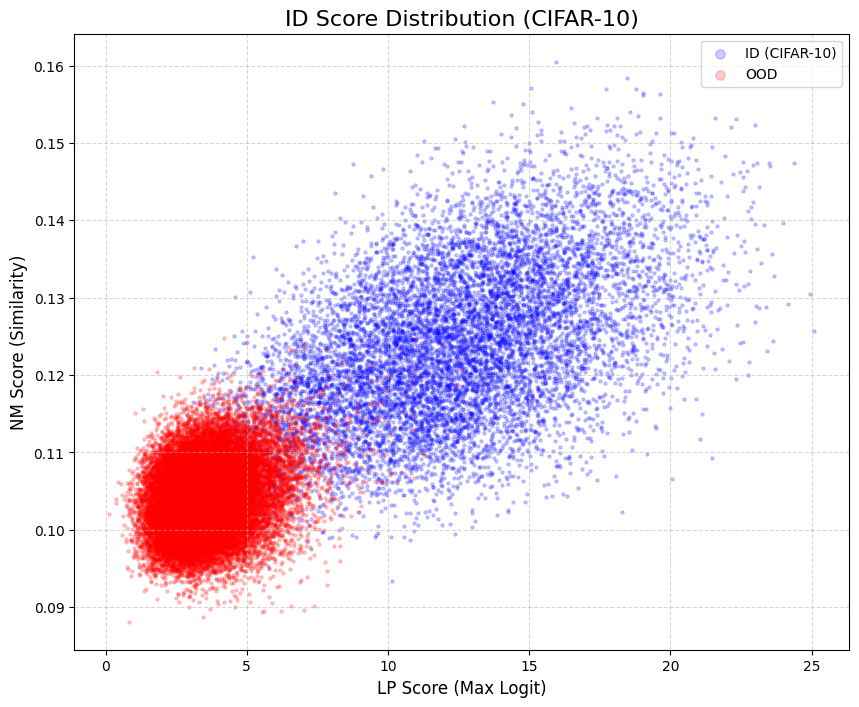

In [60]:
plot_score_distributions(
    cifar10_id_score_vectors,
    svhn_score_vectors,
    title="ID Score Distribution (CIFAR-10)"
)

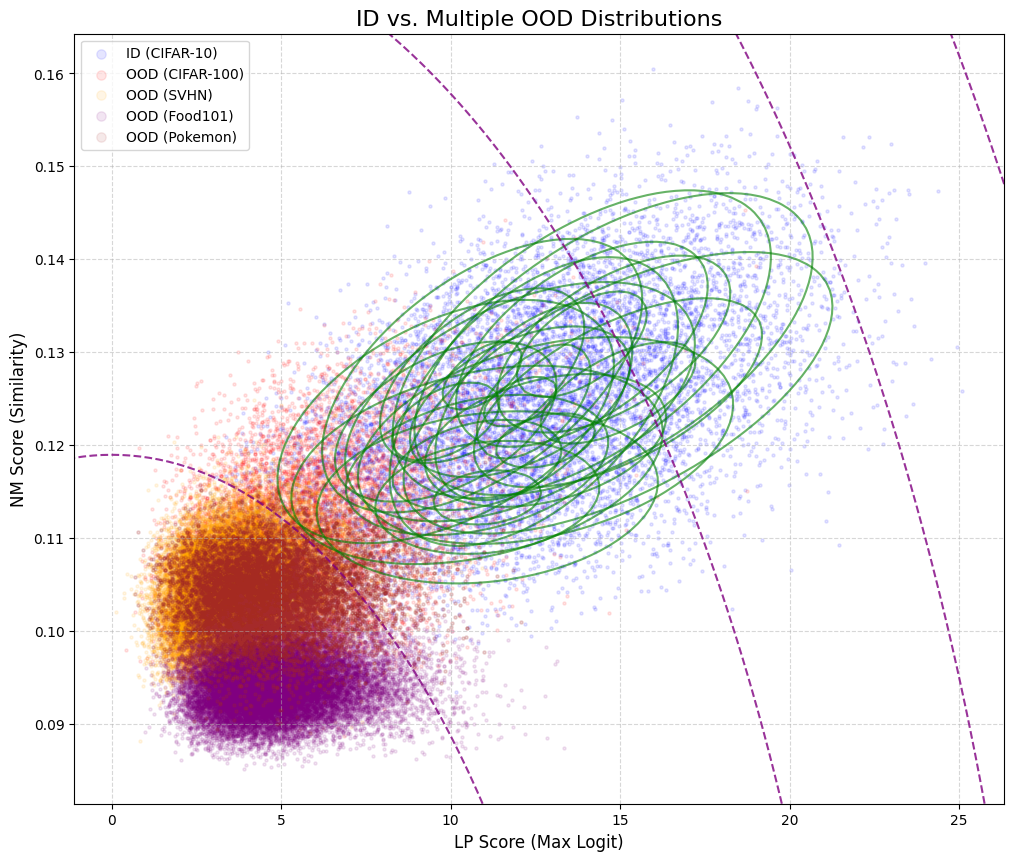

In [74]:
plot_score_distributions_with_gaussians(
    id_scores=cifar10_id_score_vectors,
    id_class_means=cifar10_id_class_score_means,
    id_class_covs=cifar10_id_class_covs,
    ood_datasets=ood_data_to_plot,
    ood_model_mean=cifar10_ood_mean,
    ood_model_cov=cifar10_ood_cov,
    id_name="ID (CIFAR-10)",
    title="ID vs. Multiple OOD Distributions"
)

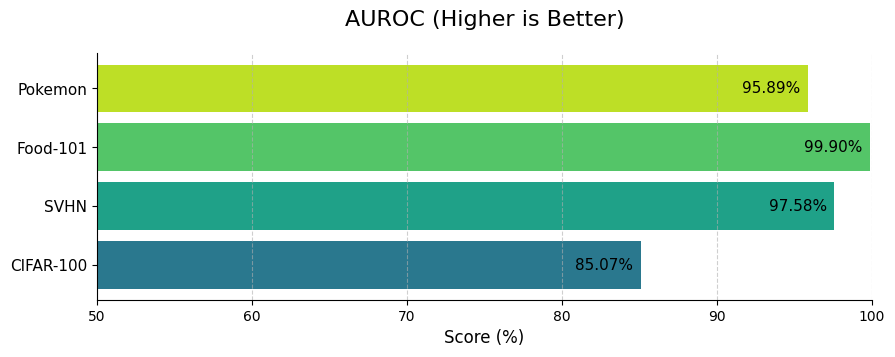

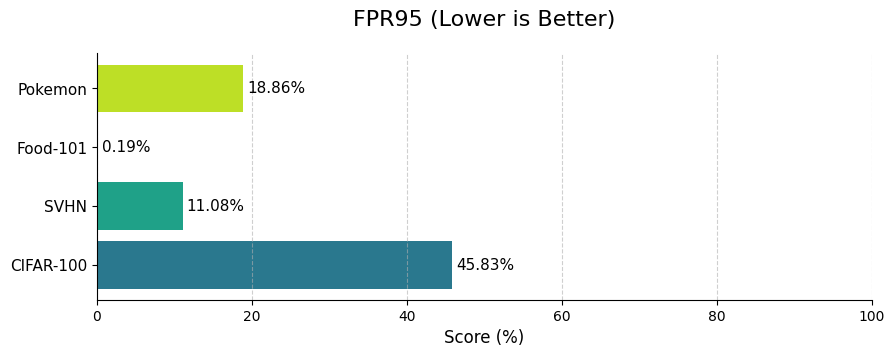

In [91]:
plot_metrics(results_auroc, "AUROC (Higher is Better)", lower_is_better=False)
plot_metrics(results_fpr95, "FPR95 (Lower is Better)", lower_is_better=True)